# B0 → B3 · 02. B1: fine-tune FaceNet trên ảnh mặt thật đeo khẩu trang giả

**Đồ án CV nâng cao · 20/11/2026**

Theo bài báo của Anwar & Raychowdhury (2020): train FaceNet trên ảnh mặt thật có khẩu trang giả. Bài báo train lại từ đầu trên 360.000 ảnh (VGGFace2-mini), còn nhóm chỉ có vài nghìn ảnh LFW, nên ở đây **fine-tune nhẹ**: giữ gần hết mạng, chỉ mở các khối cuối, BatchNorm giữ nguyên thống kê, learning rate nhỏ. Rút kinh nghiệm từ bước 6–7: fine-tune toàn bộ mạng trên dữ liệu khác miền làm model quên đặc trưng của mặt thật.

Mỗi epoch chấm trên dev LFW (người chưa thấy lúc train) với ba biến thể query: rõ mặt, khẩu trang giả, kính giả. Epoch được chọn theo Rank-1 trung bình của ba biến thể.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, gc, math, platform, inspect, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
import torch


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/cai_tien_B0_B3/cai_tien.py').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/cai_tien_B0_B3'
sys.path.insert(0, str(HERE)); sys.path.insert(0, str(ROOT / 'ban_giao_nhom/huan_luyen'))
import cai_tien
from cai_tien import FaceAligner, ArcFace, add_occlusion, facenet_embed, templates, best_match
from tai_model import load_encoder
LFW_DIR = ROOT / 'data/external/lfw/images'
ARCFACE_PATH = ROOT / 'data/external/arcface/w600k_r50.onnx'
SPLIT_DIR = HERE / 'outputs_01_du_lieu'
SEED = 20261120
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
START = time.perf_counter()


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def seed_of(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:16], 16)


def vn(x, d=1):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x, d=1):
    return vn(100 * x, d) + '%'


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
COLORS = {'B0': '#8a8984', 'B1': '#2a78d6', 'B2': '#1baf7a', 'B3': '#eb6834'}

OUT = HERE / 'outputs_02_train_B1'; TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE]:
    p.mkdir(parents=True, exist_ok=True)


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g'); return d


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)

from torch import nn
import torch.nn.functional as F
from facenet_pytorch import InceptionResnetV1
CFG = {'epochs': 8, 'warmup_epochs': 1, 'batch_size': 32, 'lr_head': 1e-3, 'lr_encoder': 2e-5, 'weight_decay': 1e-4,
       'open_layers': ['repeat_3', 'block8', 'last_linear', 'last_bn'], 'bn_running_stats': 'frozen',
       'occlusion_probability': 0.5, 'mask_share': 0.7, 'hflip_probability': 0.5, 'seed': SEED,
       'selection': 'max mean dev Rank-1 over clean/mask/sunglasses; tie: earlier epoch'}
display(pd.DataFrame([{'mục': k, 'giá trị': str(v)} for k, v in CFG.items()]))

,mục,giá trị
0,epochs,8
1,warmup_epochs,1
2,batch_size,32
3,lr_head,0.001
4,lr_encoder,2e-05
5,weight_decay,0.0001
6,open_layers,"['repeat_3', 'block8', 'last_linear', 'last_bn']"
7,bn_running_stats,frozen
8,occlusion_probability,0.5
9,mask_share,0.7


## 1. Ảnh train và dev

Ảnh train cắt sẵn 160×160 theo khung mặt (kèm mốc mặt trong ảnh cắt) để che giả và lật ngang ngay lúc train. Ảnh dev: che giả trên ảnh gốc rồi mới cắt, giống cách app xử lý.

In [2]:
SPLIT = pd.read_csv(SPLIT_DIR / 'lfw_split.csv', dtype=str, keep_default_na=False)
with np.load(SPLIT_DIR / 'lfw_split_detections.npz', allow_pickle=False) as z:
    assert z['image_id'].tolist() == SPLIT.image_id.tolist()
    DET = [{'box': b, 'landmarks': l} for b, l in zip(z['box'], z['lm'])]
for r in SPLIT.sample(64, random_state=0).itertuples():
    assert sha(ROOT / r.path) == r.sha256


def prepare(i, kind='clean'):
    r = SPLIT.iloc[i]; im = Image.open(ROOT / r.path).convert('RGB')
    if kind != 'clean':
        im = Image.fromarray(add_occlusion(im, DET[i]['landmarks'], kind, np.random.default_rng(int(r.occlusion_seed))))
    return FaceAligner.crop160(im, DET[i])


tr = np.flatnonzero(SPLIT.role.eq('train').to_numpy())
with ThreadPoolExecutor(max_workers=6) as pool:
    out = list(pool.map(prepare, tr))
TRAIN_X = np.stack([o[0] for o in out]); TRAIN_LM = np.stack([o[1] for o in out])
labels = {x: i for i, x in enumerate(sorted(SPLIT.iloc[tr].identity.unique()))}
TRAIN_Y = np.array([labels[x] for x in SPLIT.iloc[tr].identity], dtype=np.int64)
DEV = {}
dev_idx = np.flatnonzero(SPLIT.role.ne('train').to_numpy())
for kind in ['clean', 'mask', 'sunglasses']:
    with ThreadPoolExecutor(max_workers=6) as pool:
        DEV[kind] = np.stack([o[0] for o in pool.map(lambda i: prepare(i, kind), dev_idx)])
DEV_FRAME = SPLIT.iloc[dev_idx].reset_index(drop=True)
display(Markdown(f'Train: **{len(TRAIN_X)} ảnh, {len(labels)} người**. Dev: {len(DEV_FRAME)} ảnh × 3 biến thể.'))

Train: **3734 ảnh, 406 người**. Dev: 1715 ảnh × 3 biến thể.

## 2. Cách chấm trên dev

Gallery = 2 ảnh rõ mặt mỗi người quen (template trung bình). Query người quen và người lạ ở cả ba biến thể. Rank-1 không cần ngưỡng nên dùng để chọn epoch; DIR tại FPIR ≤ 5% được báo thêm, với ngưỡng chọn trên query rõ mặt (cách của B0/B1).

In [3]:
g_mask = DEV_FRAME.role.eq('dev_gallery').to_numpy()
q_mask = ~g_mask
Q = DEV_FRAME[q_mask].reset_index(drop=True)
known = Q.role.eq('dev_known_query').to_numpy()


def choose_threshold(score, correct, known):
    cand = np.r_[np.unique(score).astype(np.float64), np.inf]
    hit = np.sort(score[known & correct]); unk = np.sort(score[~known])
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    ok = FPIR <= .05
    return float(cand[ok & (DIR == DIR[ok].max())].max())


def dev_eval(model):
    model.classify = False; model.eval()
    emb = {k: facenet_embed(model, list(v)) for k, v in DEV.items()}
    names, T = templates(emb['clean'][g_mask], DEV_FRAME.identity[g_mask].to_numpy())
    res = {}
    for kind in DEV:
        idx, score = best_match(emb[kind][q_mask], [T])
        correct = known & (np.asarray(names)[idx] == Q.identity.to_numpy())
        res[kind] = (score.astype(np.float32), correct)
    t = choose_threshold(*res['clean'], known)
    row = {}
    for kind, (score, correct) in res.items():
        acc = score >= t
        row[f'Rank-1 {kind}'] = float(correct[known].mean()); row[f'DIR {kind}'] = float((acc & correct)[known].mean())
        row[f'FPIR {kind}'] = float(acc[~known].mean())
    row['Rank-1 trung bình'] = float(np.mean([row[f'Rank-1 {k}'] for k in DEV])); row['ngưỡng'] = t
    return row


b0 = load_encoder('B0', device=DEVICE)
B0_DEV = dev_eval(b0); del b0
display(pd.DataFrame([{'model': 'B0', **B0_DEV}]).round(4))

,model,Rank-1 clean,DIR clean,FPIR clean,Rank-1 mask,DIR mask,FPIR mask,Rank-1 sunglasses,DIR sunglasses,FPIR sunglasses,Rank-1 trung bình,ngưỡng
0,B0,0.9948,0.9778,0.05,0.7588,0.3559,0.0217,0.8488,0.4941,0.0183,0.8674,0.6094


## 3. Train

Epoch 0 chỉ học classifier (encoder đóng băng). Các epoch sau mở `repeat_3`, `block8` và lớp chiếu cuối. Mỗi ảnh train có 50% khả năng bị che (70% khẩu trang, 30% kính), 50% bị lật ngang; seed theo (epoch, ảnh) nên chạy lại ra cùng kết quả.

In [4]:
torch.manual_seed(SEED); np.random.seed(SEED % 2**32)
model = InceptionResnetV1(pretrained='vggface2', classify=True, num_classes=len(labels)).to(DEVICE)
OPEN = tuple(p + '.' for p in CFG['open_layers'])
encoder_params = [p for n, p in model.named_parameters() if n.startswith(OPEN)]
optimizer = torch.optim.AdamW([{'params': model.logits.parameters(), 'lr': CFG['lr_head']},
                               {'params': encoder_params, 'lr': CFG['lr_encoder']}], weight_decay=CFG['weight_decay'])
FLIP = [1, 0, 2, 4, 3]


def augment(i, epoch):
    rng = np.random.default_rng(seed_of(SEED, 'train', epoch, i))
    x, lm = TRAIN_X[i], TRAIN_LM[i]
    if rng.random() < CFG['occlusion_probability']:
        x = add_occlusion(x, lm, 'mask' if rng.random() < CFG['mask_share'] else 'sunglasses', rng)
    if rng.random() < CFG['hflip_probability']:
        x = x[:, ::-1]
    return np.ascontiguousarray(x)


def set_mode(stage):
    model.classify = True; model.eval(); model.logits.train()
    for n, p in model.named_parameters():
        p.requires_grad_(n.startswith('logits.') or (stage == 'fine' and n.startswith(OPEN)))
    if stage == 'fine':
        for layer in CFG['open_layers']:
            getattr(model, layer).train()
        model.dropout.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()


HIST, best = [{'epoch': -1, 'stage': 'B0', **B0_DEV}], None
CKPT = HERE / 'checkpoints'; CKPT.mkdir(exist_ok=True)
for epoch in range(CFG['epochs']):
    stage = 'warmup' if epoch < CFG['warmup_epochs'] else 'fine'; set_mode(stage)
    order = np.random.default_rng(seed_of(SEED, 'order', epoch)).permutation(len(TRAIN_X))
    loss_sum, hits, begin = 0., 0, time.perf_counter()
    for s in range(0, len(order), CFG['batch_size']):
        idx = order[s:s + CFG['batch_size']]
        x = torch.from_numpy(np.stack([augment(i, epoch) for i in idx])).permute(0, 3, 1, 2).float()
        x = ((x - 127.5) / 128).to(DEVICE); y = torch.from_numpy(TRAIN_Y[idx]).to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x); loss = F.cross_entropy(logits, y); loss.backward(); optimizer.step()
        loss_sum += float(loss) * len(idx); hits += int((logits.argmax(1) == y).sum())
    row = {'epoch': epoch, 'stage': stage, 'train_loss': loss_sum / len(order), 'train_acc': hits / len(order),
           'train_seconds': time.perf_counter() - begin, **dev_eval(model)}
    HIST.append(row)
    if stage == 'fine' and (best is None or row['Rank-1 trung bình'] > best['Rank-1 trung bình']):
        best = row
        torch.save({'encoder_state': {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if not k.startswith('logits.')},
                    'branch': 'B1_LFW_mask', 'epoch': epoch, 'metrics': {k: v for k, v in row.items() if isinstance(v, float) and k != 'train_seconds'},
                    'config': CFG, 'train_identities': len(labels), 'train_images': len(TRAIN_X)}, CKPT / 'B1_LFW_mask_encoder.pt')
    print(f"epoch {epoch} ({stage}): loss {row['train_loss']:.3f}, dev Rank-1 rõ/khẩu trang/kính "
          f"{row['Rank-1 clean']:.3f}/{row['Rank-1 mask']:.3f}/{row['Rank-1 sunglasses']:.3f}", flush=True)
HIST = save(pd.DataFrame(HIST), '01_training_history')
display(HIST.drop(columns=['stage']).round(4))

epoch 0 (warmup): loss 3.541, dev Rank-1 rõ/khẩu trang/kính 0.995/0.759/0.849


epoch 1 (fine): loss 0.628, dev Rank-1 rõ/khẩu trang/kính 0.995/0.819/0.897


epoch 2 (fine): loss 0.329, dev Rank-1 rõ/khẩu trang/kính 0.995/0.840/0.901


epoch 3 (fine): loss 0.267, dev Rank-1 rõ/khẩu trang/kính 0.996/0.841/0.907


epoch 4 (fine): loss 0.215, dev Rank-1 rõ/khẩu trang/kính 0.996/0.836/0.904


epoch 5 (fine): loss 0.178, dev Rank-1 rõ/khẩu trang/kính 0.996/0.853/0.913


epoch 6 (fine): loss 0.171, dev Rank-1 rõ/khẩu trang/kính 0.996/0.840/0.914


epoch 7 (fine): loss 0.146, dev Rank-1 rõ/khẩu trang/kính 0.995/0.842/0.901


,epoch,Rank-1 clean,DIR clean,FPIR clean,Rank-1 mask,DIR mask,FPIR mask,Rank-1 sunglasses,DIR sunglasses,FPIR sunglasses,Rank-1 trung bình,ngưỡng,train_loss,train_acc,train_seconds
0,-1,0.9948,0.9778,0.0500,0.7588,0.3559,0.0217,0.8488,0.4941,0.0183,0.8674,0.6094,NaN,NaN,NaN
1,0,0.9948,0.9778,0.0500,0.7588,0.3559,0.0217,0.8488,0.4941,0.0183,0.8674,0.6094,3.5411,0.4264,6.6314
2,1,0.9948,0.9752,0.0500,0.8188,0.4759,0.0183,0.8970,0.5463,0.0067,0.9035,0.6216,0.6275,0.8527,7.8171
3,2,0.9948,0.9713,0.0483,0.8396,0.4811,0.0267,0.9009,0.5411,0.0133,0.9118,0.6251,0.3286,0.9154,7.8009
4,3,0.9961,0.9700,0.0467,0.8409,0.4928,0.0217,0.9074,0.5789,0.0100,0.9148,0.6177,0.2671,0.9272,8.0080
5,4,0.9961,0.9648,0.0450,0.8357,0.4485,0.0183,0.9035,0.5398,0.0117,0.9118,0.6372,0.2153,0.9419,8.0907
6,5,0.9961,0.9687,0.0450,0.8527,0.5319,0.0217,0.9126,0.5711,0.0117,0.9205,0.6177,0.1785,0.9515,8.2740
7,6,0.9961,0.9713,0.0483,0.8396,0.5241,0.0233,0.9140,0.6023,0.0133,0.9166,0.6082,0.1707,0.9558,8.5621
8,7,0.9948,0.9687,0.0433,0.8422,0.5280,0.0267,0.9009,0.5632,0.0100,0.9126,0.6096,0.1462,0.9588,8.3122


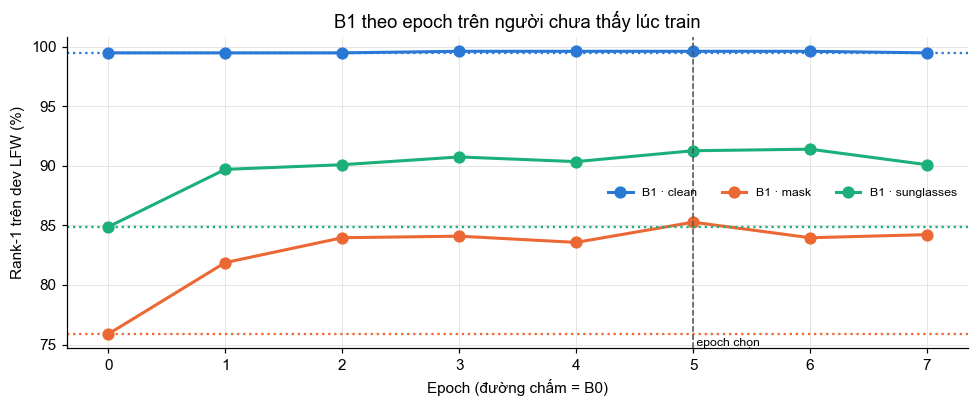

## 4. Kết luận

Epoch được chọn: **5**. Trên dev LFW, Rank-1 của B1 so với B0: rõ mặt 99,6% (+0.1 điểm), khẩu trang giả 85,3% (+9.4), kính giả 91,3% (+6.4). Encoder lưu ở `checkpoints/B1_LFW_mask_encoder.pt`. Dev là ảnh che giả; kết quả trên che thật nằm ở notebook 03.


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
h = HIST[HIST.epoch >= 0]
for kind, color in [('clean', '#2a78d6'), ('mask', '#eb6834'), ('sunglasses', '#1baf7a')]:
    ax.plot(h.epoch, 100 * h[f'Rank-1 {kind}'], 'o-', color=color, lw=2, ms=7, label=f'B1 · {kind}')
    ax.axhline(100 * B0_DEV[f'Rank-1 {kind}'], color=color, ls=':', lw=1.5)
ax.axvline(best['epoch'], color='#52514e', lw=1, ls='--'); ax.text(best['epoch'], ax.get_ylim()[0], ' epoch chọn', fontsize=8, va='bottom')
ax.set(xlabel='Epoch (đường chấm = B0)', ylabel='Rank-1 trên dev LFW (%)', title='B1 theo epoch trên người chưa thấy lúc train')
ax.legend(frameon=False, fontsize=8, ncols=3); fig.tight_layout(); finish(fig, '01_dev_rank1_by_epoch')
diff = {k: best[f'Rank-1 {k}'] - B0_DEV[f'Rank-1 {k}'] for k in ['clean', 'mask', 'sunglasses']}
json.dump({'checks': 'PASS', 'config': CFG, 'best_epoch': best['epoch'], 'B0_dev': B0_DEV, 'B1_dev': best,
           'checkpoint_sha256': sha(CKPT / 'B1_LFW_mask_encoder.pt'), 'executed_at_utc': datetime.now(timezone.utc).isoformat(),
           'elapsed_seconds': time.perf_counter() - START}, open(OUT / 'execution_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=str)
display(Markdown(f"""## 4. Kết luận

Epoch được chọn: **{best['epoch']}**. Trên dev LFW, Rank-1 của B1 so với B0: rõ mặt {pct(best['Rank-1 clean'])} ({100 * diff['clean']:+.1f} điểm), khẩu trang giả {pct(best['Rank-1 mask'])} ({100 * diff['mask']:+.1f}), kính giả {pct(best['Rank-1 sunglasses'])} ({100 * diff['sunglasses']:+.1f}). Encoder lưu ở `checkpoints/B1_LFW_mask_encoder.pt`. Dev là ảnh che giả; kết quả trên che thật nằm ở notebook 03.
""".replace('+', '+')))